# Pronóstico de demanda a un día

Actividad 6.1. Fanaee-T (2013), Bike Sharing, UCI, https://doi.org/10.24432/C5W894, CC BY 4.0. Se usan viajes diarios de Capital Bikeshare. Los costos de planeación son hipotéticos. El pronóstico se actualiza diariamente con demanda pasada observada.


## Cómo trabajar
Abra este archivo en Colab o Jupyter y ejecute de arriba hacia abajo. Mantenga la carpeta datos junto al notebook o cargue el ZIP correspondiente en Colab. La descarga automática es una alternativa, no un requisito si dispone del archivo. El código es una demostración: las interpretaciones y decisiones del reporte son trabajo del estudiante. No cargue información confidencial.


In [1]:
from pathlib import Path
import io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
print('Versiones:', 'pandas', pd.__version__, 'sklearn', sklearn.__version__)

def abrir_datos(nombre, url):
    # En local: conservar la carpeta datos junto al notebook.
    # En Colab: puede cargar el ZIP en Archivos; si no está, se descarga de UCI.
    candidatos = [Path('datos')/nombre, Path(nombre)]
    for p in candidatos:
        if p.exists():
            return zipfile.ZipFile(p)
    try:
        contenido = urllib.request.urlopen(url, timeout=60).read()
        return zipfile.ZipFile(io.BytesIO(contenido))
    except Exception as e:
        raise RuntimeError('Cargue el ZIP de la carpeta datos en Archivos de Colab y ejecute de nuevo.') from e


Versiones: pandas 2.2.3 sklearn 1.6.1


In [35]:
z=abrir_datos('bike.zip','https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip')
df=pd.read_csv(z.open('day.csv'),parse_dates=['dteday']).sort_values('dteday').reset_index(drop=True)
assert df.dteday.is_unique
assert (df.casual+df.registered==df.cnt).all()
# print(f" the dataframe cnt property {df.cnt.shift(2).head(10)}")
# print(f'iloc 3 {df.iloc[[1]]}')

df['lag1']=df.cnt.shift(1)
df['lag7']=df.cnt.shift(7)
df['media7']=df.cnt.shift(1).rolling(7).mean()
df['dia_semana']=df.dteday.dt.dayofweek
df['mes_sin']=np.sin(2*np.pi*df.dteday.dt.month/12)
df['mes_cos']=np.cos(2*np.pi*df.dteday.dt.month/12)
df['tendencia']=np.arange(len(df))
# print(f"the value of df['mes_cos'] is {df['mes_cos']} ")
df=df.dropna().reset_index(drop=True)
cols=['lag1','lag7','media7','dia_semana','mes_sin','mes_cos','tendencia','holiday','workingday']
X=df[cols];y=df.cnt
assert not {'cnt','casual','registered','temp','atemp','hum','windspeed'}&set(cols)
n=len(df);a=int(.6*n);b=int(.8*n)
Xtr,Xval,Xte=X.iloc[:a],X.iloc[a:b],X.iloc[b:]
ytr,yval,yte=y.iloc[:a],y.iloc[a:b],y.iloc[b:]
print('Fechas:',df.dteday.iloc[0],df.dteday.iloc[a],df.dteday.iloc[b],df.dteday.iloc[-1])


iloc 3    instant     dteday  season  yr  mnth  holiday  weekday  workingday  \
1        2 2011-01-02       1   0     1        0        0           0   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
1           2  0.363478  0.353739  0.696087   0.248539     131         670   

   cnt  
1  801  
Fechas: 2011-01-08 00:00:00 2012-03-17 00:00:00 2012-08-09 00:00:00 2012-12-31 00:00:00


## Comparar y seleccionar antes de prueba
No se usan clima observado ni componentes de la demanda del día objetivo. Los rezagos de cada día de prueba son válidos para un paso diario con observaciones anteriores disponibles, no para un pronóstico de todos los días desde el inicio del bloque.


In [30]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
modelos={'Ridge':make_pipeline(StandardScaler(),Ridge(alpha=10)), 'Bosque':RandomForestRegressor(n_estimators=100,max_depth=8,min_samples_leaf=5,random_state=24,n_jobs=1)}
print(f'el valor de Xval es {Xval.lag1}')

filas=[{'modelo':'Persistencia','MAE':mean_absolute_error(yval,Xval.lag1)}]
for nombre,m in modelos.items():
    m.fit(Xtr,ytr)
    filas.append({'modelo':nombre,'MAE':mean_absolute_error(yval,m.predict(Xval))})
tabla=pd.DataFrame(filas).sort_values('MAE')
print(f"el valor de la tabla en iloc0 es {tabla.iloc[0]}")
elegido=tabla.iloc[0]['modelo']
print('Validación:',tabla.to_string(index=False))
pred=Xte.lag1.to_numpy() if elegido=='Persistencia' else modelos[elegido].predict(Xte)
print('Seleccionado:',elegido)
print('Prueba MAE:',mean_absolute_error(yte,pred),'RMSE:',np.sqrt(mean_squared_error(yte,pred)))
print('Base prueba MAE:',mean_absolute_error(yte,Xte.lag1))
# Costos por viaje sub/sobreestimado: supuestos, no importes reales.
costo=4*np.maximum(yte.to_numpy()-pred,0)+np.maximum(pred-yte.to_numpy(),0)
print('Costo medio hipotético:',costo.mean())


el valor de Xval es 434    4378.0
435    7836.0
436    5892.0
437    6153.0
438    6093.0
        ...  
574    7175.0
575    6824.0
576    5464.0
577    7013.0
578    7273.0
Name: lag1, Length: 145, dtype: float64
el valor de la tabla en iloc0 es modelo         Ridge
MAE       774.989165
Name: 1, dtype: object
Validación:       modelo         MAE
       Ridge  774.989165
Persistencia  896.082759
      Bosque 1490.958664
Seleccionado: Ridge
Prueba MAE: 892.060718176866 RMSE: 1211.5936782316742
Base prueba MAE: 886.9172413793103
Costo medio hipotético: 2255.782815184551


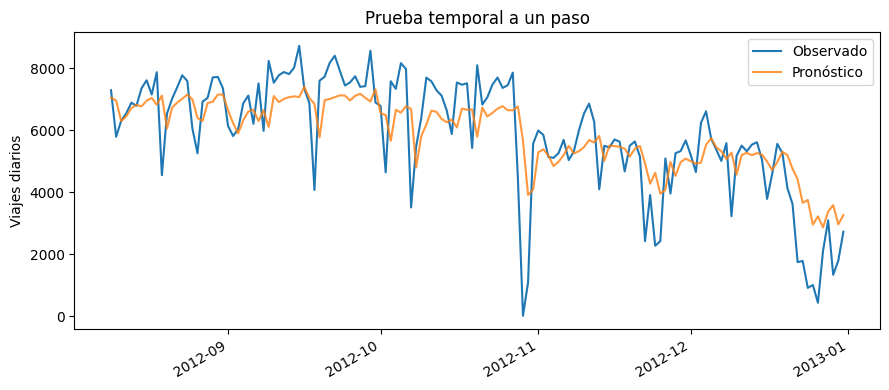

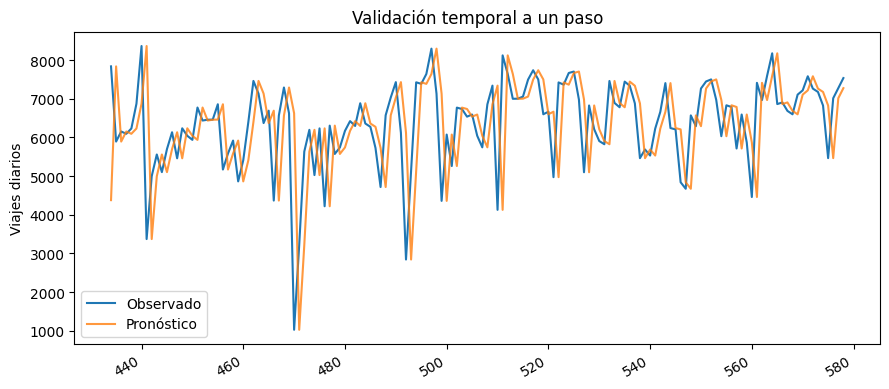

In [29]:
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(df.dteday.iloc[b:],yte,label='Observado')
ax.plot(df.dteday.iloc[b:],pred,label='Pronóstico',alpha=.8)
ax.set(ylabel='Viajes diarios',title='Prueba temporal a un paso');ax.legend()
fig.autofmt_xdate();plt.tight_layout()

fig1,ax1 =  plt.subplots(figsize=(9,4))
ax1.plot(yval,label='Observado')
ax1.plot(Xval.lag1,label='Pronóstico',alpha=.8)
ax1.set(ylabel='Viajes diarios',title='Validación temporal a un paso');ax1.legend()
fig1.autofmt_xdate();plt.tight_layout()



## Trabajo propio
Discuta si un modelo supera realmente la persistencia, y qué haría si no la supera. Traduzca errores a límites de planeación; no convierta viajes directamente en número de bicicletas. Extensión: validación de origen rodante dentro de entrenamiento/validación, sin usar prueba para elegir hiperparámetros.


##Discuta si un modelo supera realmente la persistencia
**Qué haría si no la supera? Traduzca errores a límites de planeación; no convierta viajes directamente en número de bicicletas.**

El modelo de Ridge presenta un error medio absoluto mejor que el promedio movil o la estimación con valores rezagados, lo cual es el modelo de persistencia.

El modelo de persistencia asume que la estimación de demanda de bicicletas del dia siguiente sera la misma que aquella del dia anterior. Esto puede presentar problemas pues no se consideran otras variables tales como el clima, la temperatura o bien el dia de la semana, lo cual puede determinar la demanda del dia anterior, El cual podria ser Domingo pero el siguiente dia (Lunes) el  clima es malo pues puede llover, y hacer frio.

El modelo de persistencia esta limitado a la particion de la informacion entre a y b, las cuales dependen del numero n, es decir la cantidad de filas en el archivo CSV.

Extensión: validación de origen rodante dentro de entrenamiento/validación, sin usar prueba para elegir hiperparámetros.


No habia comprendido a que se referia la instruccion con el termino "origen rodante" pero al interactuar con Gemini, entendi que se busca hacer la comparacion con el modelo de intervalos de series de tiempo al entrenar con cada vez mas data (los folds) y siempre validar esta información con los datos observados siguientes.

Aun asi, se muestra que el modelo de "Perseverancia" o bien Lag 1 y 7 es tiene un error de estimación menor (Mean Absolute Error) y por lo tanto puede ser mejor usar este modelo.

Adicionalmente, me gustaria comentar que la estimación es util pero el verdadero valor del modelo y la estimación yace en entender que el modelo que menos se equivoque sera mejor y que el sentido o bien interpretación que se le debe dar al modelo es la cantidad de inventario (bicicletas) sobrante que se debe tener para hacer frente a una subestimación de la demanda.

### Extensión: Validación de Origen Rodante (TimeSeriesSplit)
Implementamos una búsqueda de hiperparámetros (afinación de `alpha` para Ridge) utilizando una validación cruzada que respeta el orden temporal sobre el conjunto combinado de Entrenamiento + Validación, protegiendo completamente el conjunto de Prueba (`Xte`, `yte`).

In [42]:
from sklearn.model_selection import TimeSeriesSplit
import pandas as pd
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

# 1. Combinamos entrenamiento y validación originales para nuestra validación temporal interna
X_train_val = pd.concat([Xtr, Xval])
y_train_val = pd.concat([ytr, yval])

# 2. Definimos el generador de origen rodante (5 divisiones temporales)
tscv = TimeSeriesSplit(n_splits=5)

# 3. Definimos un rango de hiperparámetros 'alpha' para Ridge que deseamos probar
alphas = [0.1, 1.0, 10.0, 50.0, 100.0, 500.0]
resultados_busqueda = []

print("--- Iniciando Validación de Origen Rodante ---\n")
iCounter = 0
for alpha in alphas:
    maes_folds = []
    # Iteramos sobre cada ventana temporal desplazando el origen

    for fold, (train_index, val_index) in enumerate(tscv.split(X_train_val)):
        # Segmentamos los datos respetando la línea temporal
        X_tr_fold, X_val_fold = X_train_val.iloc[train_index], X_train_val.iloc[val_index]
        y_tr_fold, y_val_fold = y_train_val.iloc[train_index], y_train_val.iloc[val_index]
        # iCounter +=1
        # if iCounter==1:
        #   print(f'Xtrain_Val fold en el indice {train_index} es {X_train_val.iloc[train_index]}')
        #   #imprimo los valores de XTR_Fold para enteender que esta pasando


        # Instanciamos y entrenamos el pipeline
        modelo_temp = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        modelo_temp.fit(X_tr_fold, y_tr_fold)

        # Evaluamos en el bloque del futuro inmediato
        pred_fold = modelo_temp.predict(X_val_fold)
        mae = mean_absolute_error(y_val_fold, pred_fold)
        maes_folds.append(mae)

    # Promedio de errores del parámetro a lo largo de todas las ventanas temporales
    mae_promedio = np.mean(maes_folds)
    resultados_busqueda.append({'alpha': alpha, 'MAE_promedio': mae_promedio})
    print(f"Alpha: {alpha:5.1f} | MAE Promedio en Folds: {mae_promedio:.2f}")

# 4. Seleccionamos el mejor alpha
df_resultados = pd.DataFrame(resultados_busqueda).sort_values('MAE_promedio')
mejor_alpha = df_resultados.iloc[0]['alpha']
print(f"\nMejor Alpha seleccionado mediante origen rodante: {mejor_alpha}")

# 5. Entrenamos el modelo final con el mejor alpha usando TODOS los datos de train_val
modelo_final = make_pipeline(StandardScaler(), Ridge(alpha=mejor_alpha))
modelo_final.fit(X_train_val, y_train_val)

# 6. Evaluamos una única vez contra el conjunto de prueba (Test) que estuvo totalmente oculto
pred_final_test = modelo_final.predict(Xte)
mae_final_test = mean_absolute_error(yte, pred_final_test)
print(f"MAE Final en el conjunto de prueba (Test): {mae_final_test:.2f}")


--- Iniciando Validación de Origen Rodante ---

Alpha:   0.1 | MAE Promedio en Folds: 884.76
Alpha:   1.0 | MAE Promedio en Folds: 882.73
Alpha:  10.0 | MAE Promedio en Folds: 876.01
Alpha:  50.0 | MAE Promedio en Folds: 893.74
Alpha: 100.0 | MAE Promedio en Folds: 924.32
Alpha: 500.0 | MAE Promedio en Folds: 1106.32

Mejor Alpha seleccionado mediante origen rodante: 10.0
MAE Final en el conjunto de prueba (Test): 893.36
